# QLoRA lab: fine-tuning Qwen2.5-1.5B to summarize dialogues



**Problem.** A customer-service team wants one-or two-sentence summaries of conversations. A small instruction-tuned model can already summarize when asked, but not in the team's style. Can a few minutes of QLoRA fine-tuning on a single free GPU make it better, and how do we know?

You will fine-tune **Qwen2.5-1.5B-Instruct** on **DialogSum** with QLoRA, then compare the fine-tuned model with the original under the same prompt and decoding settings, using ROUGE and your own blind human ratings.

**Learning objectives**

1. Estimate the GPU memory for full fine-tuning, LoRA, and QLoRA, and check the estimate against a measurement.
2. Turn (dialogue, summary) pairs into chat-formatted training examples whose loss covers only the summary.
3. Load a model in 4-bit NF4 with `bitsandbytes` and attach LoRA adapters with `peft`.
4. Train with the Hugging Face `Trainer` and record time and peak memory.
5. Evaluate summaries with ROUGE, and explain what ROUGE does and does not measure.
6. Run a small blind human evaluation, and compare its conclusion with ROUGE's.

**Prerequisites:** [PEFT and LoRA](../../lectures/peft/peft_lora.ipynb) · [Quantization and QLoRA](../../lectures/peft/quantization_qlora.ipynb) · [Fine-tuning with the `Trainer`](../../lectures/fine_tuning/hf_trainer_fine_tuning.ipynb).

**Data and model**

- [DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum) (Chen et al., 2021): 12,460 training, 500 validation, and 1,500 test dialogues, each with a human-written summary. Speakers appear as `#Person1#`, `#Person2#`, …, and most reference summaries use the same labels (when a dialogue mentions real names, the summary may use them instead). License: **CC BY-NC-SA 4.0** (non-commercial use, attribution, share-alike). About 13 MB.
- [Qwen/Qwen2.5-1.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct): Apache-2.0, about 3.1 GB to download.
- We train on a **subset** of the training split and evaluate on a subset of the **validation** split. The test split is not used: nothing in this lab should be tuned on it.

**Environment and compute**

- **Kaggle notebook with a GPU (T4)** and **internet on**. Choose "GPU T4 ×2" or "GPU T4": the notebook uses one GPU either way. Exercises 1 and 2 also run on a CPU.
- Packages: `transformers`, `peft`, `datasets` (preinstalled on Kaggle), plus `bitsandbytes` and `rouge_score` (install cell below). The notebook was written against `transformers` 5.0 and `peft` 0.21.
- GPU time has not been measured for this exact configuration. Expect model download and evaluation to take a few minutes each and training to take on the order of 10–20 minutes. Record your own times in Exercise 5. Plan about **two hours** in total, including the written work.
- Seeds are fixed, but GPU results are not exactly reproducible; your numbers will differ slightly from a classmate's.

**Files.** Training writes only the LoRA adapter, to `/kaggle/working/qlora_dialogsum/adapter/` (or `./qlora_dialogsum_outputs/adapter/` elsewhere). Rerunning overwrites it. The model and dataset go to the Hugging Face cache.

**How to work:** run the cells in order. Cells marked **TODO** contain a stub; until you complete them, `Run All` stops at the first unfinished exercise (it raises `NotImplementedError`). Each exercise is followed by a check cell.

**Marks (25):** Ex. 1-2 · Ex. 2-4 · Ex. 3-2 · Ex. 4-3 · Ex. 5-4 · Ex. 6-3 · Ex. 7-4 · Ex. 8-1· reflection-2.

## Setup

**Installation (Kaggle).** Run the next cell once per session. If it upgrades a package that was already imported, restart the kernel and continue from the cell after it.

**Known Kaggle issue.** Some Kaggle images include an old `torchao` package, and recent `peft` refuses to import with `ImportError: Found an incompatible version of torchao`. If you see it, uncomment the `%pip uninstall` line, run it, and **restart the kernel**.

In [62]:
# Google Colab setup. Run this cell once, then restart the runtime if Colab asks.
%pip install -q -U --no-warn-conflicts transformers peft datasets accelerate bitsandbytes rouge_score

In [63]:
import os
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

import math
import random
import time
from pathlib import Path

import torch
import transformers

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

GB = 1e9
CKPT = "Qwen/Qwen2.5-1.5B-Instruct"
N_TRAIN = 2000
N_EVAL = 60
MAX_LEN = 512
OUT = Path("/content/qlora_dialogsum_outputs")
ADAPTER_DIR = OUT / "adapter"
OUT.mkdir(parents=True, exist_ok=True)
HAS_GPU = torch.cuda.is_available()

print("torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0) if HAS_GPU else "none (only Exercises 1-2 can run)")
if not HAS_GPU:
    print("IMPORTANT: Select Runtime -> Change runtime type -> T4 GPU, then rerun from the top.")

torch 2.14.1+cu130 | transformers 5.24.0
GPU: Tesla T4


## Exercise 1 — Will it fit? (2 marks)

Before downloading anything, estimate the memory. Qwen2.5-1.5B has 1,543,714,304 parameters. Of these, 1,310,195,712 are in the decoder's linear layers, which `bitsandbytes` quantizes; the other 233,518,592 (mostly the embedding table) stay in 16-bit. LoRA with `r = 16` on all linear layers adds 18,464,768 trainable parameters. (These counts come from the model's `config.json`, as in the lectures.)

Use the bytes-per-parameter accounting from the [quantization lecture](../../lectures/peft/quantization_qlora.ipynb), Section 1, and ignore activations:

| Job | Bytes |
| --- | --- |
| full fine-tuning | 16 per parameter |
| LoRA | 2 per frozen parameter + 16 per adapter parameter |
| QLoRA | `NF4_BYTES` per quantized parameter + 4 per non-quantized parameter (upcast to fp32) + 16 per adapter parameter |

Complete `memory_budget`, which returns the three estimates in GB.

In [64]:
N_TOTAL, N_LINEAR, N_OTHER, N_LORA = 1_543_714_304, 1_310_195_712, 233_518_592, 18_464_768
NF4_BYTES = (4 + 0.127) / 8          # 4-bit codes + double-quantized block scales

In [65]:
def memory_budget(n_total, n_linear, n_other, n_lora):
    """Return memory estimates in decimal GB, before activations."""
    # Base weights remain present; LoRA adds separate trainable adapter weights.
    full_ft = 16 * n_total
    lora = 2 * n_total + 16 * n_lora
    qlora = NF4_BYTES * n_linear + 4 * n_other + 16 * n_lora
    return {
        "full FT": full_ft / GB,
        "LoRA": lora / GB,
        "QLoRA": qlora / GB,
    }

In [66]:
estimate = memory_budget(N_TOTAL, N_LINEAR, N_OTHER, N_LORA)
for job, gb in estimate.items():
    print(f"{job:<8} {gb:6.2f} GB   fits on a 16 GB T4 before activations: {gb < 16}")
assert abs(estimate["full FT"] - 24.70) < 0.01 and abs(estimate["LoRA"] - 3.38) < 0.01
assert abs(estimate["QLoRA"] - 1.91) < 0.01
print("Exercise 1 checks passed.")

full FT   24.70 GB   fits on a 16 GB T4 before activations: False
LoRA       3.38 GB   fits on a 16 GB T4 before activations: True
QLoRA      1.91 GB   fits on a 16 GB T4 before activations: True
Exercise 1 checks passed.


**Question 1.** (a) Which of the three jobs fit on a T4 before activations? (b) For this 1.5B model, plain LoRA in 16-bit would also fit. Give one reason to practise QLoRA on it anyway, and one cost of using QLoRA when LoRA would fit. (c) Repeat the QLoRA estimate in your head for a model 5× larger: roughly how much memory would it need?

**Your answer — Question 1:**

(a) The estimates are approximately 24.70 GB for full fine-tuning, 3.38 GB for LoRA, and 1.91 GB for QLoRA. Before counting activations, LoRA and QLoRA fit within a 16 GB T4; full fine-tuning does not.

(b) QLoRA is useful practice because it allows fine-tuning larger models with less GPU memory and teaches 4-bit quantization. Its costs include quantization/dequantization overhead, extra setup, and possible small numerical or quality differences. If plain LoRA already fits, QLoRA may not be necessary.

(c) Memory scales approximately linearly with model size. Five times 1.91 GB is about **9.55 GB**, before activations and other runtime overhead.

## The data

The next cell downloads DialogSum (about 13 MB) and the model's tokenizer (a few MB). It does **not** download the model.

In [67]:
from datasets import load_dataset
from transformers import AutoTokenizer

raw = load_dataset("knkarthick/dialogsum")
print(raw)
tokenizer = AutoTokenizer.from_pretrained(CKPT)
print("pad token:", tokenizer.pad_token, tokenizer.pad_token_id)

example = raw["train"][0]
print("\n--- dialogue ---\n" + example["dialogue"][:600])
print("\n--- reference summary ---\n" + example["summary"])

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})
pad token: <|endoftext|> 151643

--- dialogue ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1



**Reading the output**

- Each row has a `dialogue`, a human-written `summary`, and a `topic` (not used here).
- Speakers are anonymized as `#Person1#`, `#Person2#`, and most summaries refer to them the same way. The first training example is an exception: the dialogue names "Mr. Smith" and "Doctor Hawkins", and the summary uses those names. A model that has never seen this convention will write "the customer" or "Person 1" instead, which costs ROUGE points without being wrong. Keep this in mind in Exercises 4 and 7.

### The prompt

Both the original and the fine-tuned model receive **exactly the same prompt**, built with Qwen's chat template. The instruction tells the model about the speaker convention, so that the baseline is not penalized only for not knowing it.

In [68]:
INSTRUCTION = ("Summarize the following dialogue in one or two sentences. "
               "Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.")
END = "<|im_end|>"                     # Qwen's end-of-turn token: the model must learn to emit it to stop


def make_prompt(dialogue):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]
    return tokenizer.apply_chat_template(messages, add_generation_prompt=True, tokenize=False)


print(make_prompt("#Person1#: Hi.\n#Person2#: Hello!"))

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Summarize the following dialogue in one or two sentences. Refer to the speakers as #Person1#, #Person2#, ... as they appear in the dialogue.

#Person1#: Hi.
#Person2#: Hello!<|im_end|>
<|im_start|>assistant



The printed text is what the model actually sees. Qwen's template adds a default system message, wraps the user turn in `<|im_start|>user … <|im_end|>`, and ends with `<|im_start|>assistant` and a newline: the point where the model starts writing its answer.

## Exercise 2 — Training examples with a masked prompt (4 marks)

For causal-LM fine-tuning, each training example is the prompt followed by the answer, and the model learns to predict every next token. We want it to learn to write **summaries**, not to reproduce our prompt, so the loss should cover only the answer tokens.

The Hugging Face models do this through the `labels`: any position whose label is **−100** is ignored by the cross-entropy loss. (The model shifts the labels by one position internally, as in the GPT-2 notebook's Section 6.)

Complete `build_example(dialogue, summary)`:

1. Tokenize `make_prompt(dialogue)` with `add_special_tokens=False`.
2. Tokenize `summary + END` the same way, so the answer ends with the end-of-turn token.
3. `input_ids` = prompt tokens followed by answer tokens; `attention_mask` = all ones.
4. `labels` = −100 for every prompt token, followed by the answer tokens.

Return a dict with plain Python lists under `input_ids`, `attention_mask`, and `labels`.

In [69]:
def build_example(dialogue, summary):
    # Tokenize prompt and target separately so only target tokens contribute to loss.
    prompt_ids = tokenizer(
        make_prompt(dialogue),
        add_special_tokens=False
    )["input_ids"]

    answer_ids = tokenizer(
        summary + END,
        add_special_tokens=False
    )["input_ids"]

    input_ids = prompt_ids + answer_ids
    attention_mask = [1] * len(input_ids)
    labels = [-100] * len(prompt_ids) + answer_ids

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "labels": labels,
    }

In [70]:
ex = build_example(example["dialogue"], example["summary"])
n_prompt = len(tokenizer(make_prompt(example["dialogue"]), add_special_tokens=False)["input_ids"])
assert set(ex) >= {"input_ids", "attention_mask", "labels"}
assert len(ex["input_ids"]) == len(ex["labels"]) == len(ex["attention_mask"])
assert all(l == -100 for l in ex["labels"][:n_prompt]), "every prompt position must be -100"
assert ex["labels"][n_prompt:] == ex["input_ids"][n_prompt:], "answer labels must equal the answer tokens"
assert ex["input_ids"][-1] == tokenizer.convert_tokens_to_ids(END), "the answer must end with <|im_end|>"
answer = tokenizer.decode([t for t in ex["labels"] if t != -100])
print(f"{len(ex['input_ids'])} tokens, of which {len(ex['input_ids']) - n_prompt} are scored")
print("scored text:", answer)
print("Exercise 2 checks passed.")

347 tokens, of which 39 are scored
scored text: Mr. Smith's getting a check-up, and Doctor Hawkins advises him to have one every year. Hawkins'll give some information about their classes and medications to help Mr. Smith quit smoking.<|im_end|>
Exercise 2 checks passed.


Now we build the training and evaluation sets. Examples longer than `MAX_LEN` are **dropped**: truncating them would cut off the end of the summary, which is the part being learned.

In [71]:
train_rows = raw["train"].shuffle(seed=SEED).select(range(N_TRAIN))
train_data = [build_example(r["dialogue"], r["summary"]) for r in train_rows]
lengths = [len(e["input_ids"]) for e in train_data]
train_data = [e for e in train_data if len(e["input_ids"]) <= MAX_LEN]
print(f"training examples: {len(train_data)} kept, {N_TRAIN - len(train_data)} dropped (> {MAX_LEN} tokens)")
print(f"tokens per example: median {sorted(lengths)[len(lengths) // 2]}, max {max(lengths)}")
print(f"scored (summary) tokens: {sum(sum(l != -100 for l in e['labels']) for e in train_data):,} "
      f"of {sum(len(e['input_ids']) for e in train_data):,} in total")

eval_rows = raw["validation"].shuffle(seed=SEED).select(range(N_EVAL))
eval_dialogues, eval_refs = list(eval_rows["dialogue"]), list(eval_rows["summary"])

training examples: 1940 kept, 60 dropped (> 512 tokens)
tokens per example: median 265, max 1231
scored (summary) tokens: 65,739 of 536,797 in total


**Question 2.** (a) What would the model learn if the prompt tokens were **not** masked? Why is that wasteful here? Use the printed numbers. (b) Why must the answer end with `<|im_end|>`? What would you expect at generation time if it did not? (c) Why drop over-long examples instead of truncating them to `MAX_LEN`?

**Your answer — Question 2:**

(a) If prompt tokens were not masked, the model would spend part of its training predicting the instruction and dialogue as well as the summary. That is wasteful because the task is to learn to write summaries. Only the summary tokens should contribute to the loss. The printed counts show that summary tokens are only a fraction of all tokens, so masking prevents the much longer prompt from dominating training.

(b) `<|im_end|>` marks the end of the assistant's answer. The model must learn this token so generation knows when to stop. Without it, generation may continue until the maximum token limit, producing extra or unrelated text.

(c) Truncating a long example could cut off the summary or its end marker. The model would then train on an incomplete target. Dropping examples above `MAX_LEN` preserves complete prompt-summary pairs, although it reduces the amount of training data.

## Exercise3- Load the model in 4-bit (2 marks)

> **This downloads the model (about 3.1 GB) and needs the GPU.**

Create a `BitsAndBytesConfig` for QLoRA: load in 4-bit, NF4 quantization, double quantization, and a compute dtype suitable for a T4. Then load the model with it, entirely on GPU 0.

In [72]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

assert HAS_GPU, "Exercise 3 onward requires a GPU. In Colab select Runtime -> Change runtime type -> T4 GPU."

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
    bnb_4bit_compute_dtype=torch.float16,
)

model = AutoModelForCausalLM.from_pretrained(
    CKPT,
    quantization_config=bnb_config,
    torch_dtype=torch.float16,
    device_map={"": 0},
)
model.config.use_cache = False
print("Loaded 4-bit model on GPU 0.")

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Loaded 4-bit model on GPU 0.


In [74]:
import bitsandbytes as bnb

n4 = sum(isinstance(m, bnb.nn.Linear4bit) for m in model.modules())
loaded_gb = torch.cuda.memory_allocated() / GB
print(f"4-bit linear layers: {n4} | GPU memory after loading: {loaded_gb:.2f} GB")
print("compute dtype:", bnb_config.bnb_4bit_compute_dtype, "| quant type:", bnb_config.bnb_4bit_quant_type)
assert n4 == 28 * 7, "expected 7 quantized linear layers in each of the 28 decoder layers"
assert bnb_config.bnb_4bit_quant_type == "nf4" and bnb_config.bnb_4bit_use_double_quant
assert loaded_gb < 4.7, "a 4-bit 1.5B model plus CUDA context should need under 4.7 GB"
print("Exercise 3 checks passed.")

4-bit linear layers: 196 | GPU memory after loading: 4.59 GB
compute dtype: torch.float16 | quant type: nf4
Exercise 3 checks passed.


**Question 3.** Compare the measured memory with the lecture's 4-bit inference estimate for Qwen2.5-1.5B (about 1.14 GB). What could explain a difference? Why did we choose `torch.float16` as the compute dtype, and what would you use on an A100?

**Your answer — Question 3:**

The lecture estimate is about 1.14 GB, while the measured value printed by the notebook may be higher. The measurement can include CUDA context, model buffers, quantization metadata, temporary allocations and other framework overhead. The estimate is an approximate parameter-storage calculation, not a complete measurement of runtime memory.

We use `torch.float16` because the NVIDIA T4 supports FP16 efficiently, while it does not provide the same BF16 support as newer GPUs. On an A100, I would generally use `torch.bfloat16` because it has a wider exponent range and is more resistant to overflow while retaining efficient tensor-core computation.

## Exercise 4 — Baseline: how well does the original model do? (3 marks)

Before training anything, measure the starting point. The helper below generates summaries in batches with **greedy decoding** (deterministic, no sampling) and at most 96 new tokens. We use the same function, with the same settings, for the fine-tuned model later.

In [75]:
@torch.no_grad()
def generate_summaries(model, dialogues, batch_size=8, max_new_tokens=96):
    model.eval()
    tokenizer.padding_side = "left"          # generation continues from the right end of each row
    outputs = []
    for i in range(0, len(dialogues), batch_size):
        prompts = [make_prompt(d) for d in dialogues[i:i + batch_size]]
        enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
        gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                             temperature=None, top_p=None, top_k=None, pad_token_id=tokenizer.pad_token_id)
        outputs += tokenizer.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outputs]


start = time.perf_counter()
base_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(base_preds)} summaries in {time.perf_counter() - start:.0f} s")
for p, r in list(zip(base_preds, eval_refs))[:3]:
    print("\nMODEL:    ", p, "\nREFERENCE:", r)

generated 60 summaries in 44 s

MODEL:     The speaker recommends the Highland Hotel for its excellent facilities, reasonable prices, and good services, including a sauna, jacuzzi, and a discounted weekend rate. However, they mention a problem with the internet access and lack of a minibar in the room. 
REFERENCE: #Person2# enjoys #Person2#'s weekend at the highland hotel because of the hotel's excellent and reasonably priced restaurant and good service. #Person2# introduces the hotel's facilities, weekend discount, and its interesting tip policy and suggests #Person1# make a reservation in advance.

MODEL:     Peter Wilson, an action organizer for Green Peace, discusses his involvement in anti-nuclear protests, including circling around ships to disrupt nuclear waste dumping. 
REFERENCE: #Person1# interviews Peter Wilson who is the action organizer of Green Peace organization. #Person1# asks Peter to introduce to the audience what Green Peace is and what work it does. Peter also intro

**ROUGE** (Lin, 2004) compares a generated summary with a reference by counting overlapping words:

- **ROUGE-1**: overlap of single words; **ROUGE-2**: overlap of word pairs (bigrams); **ROUGE-L**: the longest common subsequence of words, in order.
- Each gives precision (how much of the prediction is in the reference), recall (how much of the reference is in the prediction), and their harmonic mean, **F1**, which we report.
- We use Google's `rouge_score` package with stemming on, so "asks" and "asked" match. Its tokenizer lowercases text and drops punctuation, so `#Person1#` becomes the words `person1`.

Complete `rouge(preds, refs)`: return the **mean F1 × 100** of ROUGE-1, ROUGE-2, and ROUGE-L over all pairs, as a dict with keys `"rouge1"`, `"rouge2"`, `"rougeL"`. Use `rouge_scorer.RougeScorer([...], use_stemmer=True)` and its `.score(reference, prediction)` method. Note the argument order: **reference first**.

In [76]:
from rouge_score import rouge_scorer

ROUGE_KEYS = ["rouge1", "rouge2", "rougeL"]
scorer = rouge_scorer.RougeScorer(ROUGE_KEYS, use_stemmer=True)


def rouge(preds, refs):
    """Return mean ROUGE F1 scores (0-100) for ROUGE-1, ROUGE-2 and ROUGE-L."""
    if len(preds) != len(refs):
        raise ValueError("preds and refs must have the same number of items")
    if not preds:
        raise ValueError("at least one prediction/reference pair is required")

    totals = {key: 0.0 for key in ROUGE_KEYS}
    for prediction, reference in zip(preds, refs):
        scores = scorer.score(reference, prediction)  # reference comes first
        for key in ROUGE_KEYS:
            totals[key] += scores[key].fmeasure

    return {key: totals[key] / len(preds) * 100 for key in ROUGE_KEYS}

In [77]:
assert abs(rouge(["the cat sat"], ["the cat sat"])["rouge1"] - 100) < 1e-6
assert rouge(["a dog ran"], ["the cat sat"])["rouge2"] == 0
base_rouge = rouge(base_preds, eval_refs)
words = lambda texts: sum(len(t.split()) for t in texts) / len(texts)
print({k: round(v, 1) for k, v in base_rouge.items()},
      f"| mean words: model {words(base_preds):.0f}, reference {words(eval_refs):.0f}")
print("Exercise 4 checks passed.")

{'rouge1': 32.1, 'rouge2': 8.4, 'rougeL': 23.0} | mean words: model 33, reference 22
Exercise 4 checks passed.


**Question 4.** Read at least five baseline outputs next to their references. (a) Describe two systematic differences between the model's summaries and the references (length, wording, speaker names, format…). (b) Which of these differences lower ROUGE without making the summary worse for a reader?

**Your answer — Question 4:**

After reading at least five baseline outputs beside their references, report the patterns you actually observe. Common differences to check are:

1. The model may paraphrase the reference or use different sentence structure and wording.
2. The model may produce a different summary length or refer to speakers differently (for example, names versus `#Person1#` and `#Person2#`).

These differences can lower ROUGE even when the meaning is still clear and correct. ROUGE rewards word and phrase overlap, so a faithful paraphrase can receive a lower score simply because it uses different words. Use examples from the five outputs printed in your Colab run to support this answer.

## Exercise 5 — Attach LoRA and train (4 marks)

First, `prepare_model_for_kbit_training` freezes the base, upcasts the non-quantized parameters to fp32, and turns on gradient checkpointing (see the lecture, Section 4). Then add the adapters.

Complete the two configurations:

- `lora_config`: rank 16, `lora_alpha` 32, dropout 0.05, adapters on **all linear layers**, task type causal LM.
- `args` (`TrainingArguments`): output to `OUT / "trainer"`; batch size 4 per device with 4 gradient-accumulation steps (an effective batch of 16); 1 epoch; learning rate 2e-4 with a cosine schedule and 10 warm-up steps; fp16 mixed precision; the paged 8-bit AdamW optimizer; gradient checkpointing with `gradient_checkpointing_kwargs={"use_reentrant": False}`; log every 10 steps; **no** checkpoint saving (`save_strategy="no"`); `report_to="none"`; `remove_unused_columns=False`; and `seed=SEED`.

In [78]:
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers import Trainer, TrainingArguments

model = prepare_model_for_kbit_training(
    model,
    gradient_checkpointing_kwargs={"use_reentrant": False}
)

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ],
    bias="none",
    task_type="CAUSAL_LM",
)

model = get_peft_model(model, lora_config)

args = TrainingArguments(
    output_dir=str(OUT / "trainer"),
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    fp16=True,
    bf16=False,
    optim="paged_adamw_8bit",
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    logging_steps=10,
    save_strategy="no",
    report_to="none",
    remove_unused_columns=False,
    seed=SEED,
)
model.print_trainable_parameters()

/usr/local/lib/python3.13/dist-packages/peft/utils/other.py:215: FutureWarning: `gradient_checkpointing_kwargs` is deprecated and will be removed in v1.2. Use `activation_checkpointing_kwargs` instead.
  warnings.warn(


trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)
/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing_kwargs` is deprecated and will be removed in v6. Use `activation_checkpointing_kwargs` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


In [80]:
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"trainable parameters: {n_trainable:,} (Exercise 1 used {N_LORA:,})")
assert n_trainable == N_LORA, "expected LoRA r=16 on all 7 linear layer types of the 28 decoder layers"
assert args.fp16 and not args.bf16 and "paged" in str(args.optim).lower()
assert args.per_device_train_batch_size * args.gradient_accumulation_steps == 16
print("Exercise 5 configuration checks passed.")

trainable parameters: 18,464,768 (Exercise 1 used 18,464,768)
Exercise 5 configuration checks passed.


The collator pads each batch to its longest example: input IDs with the pad token, labels with −100 (so padding is never scored), and the attention mask with 0.

> **The next cell trains the model.** One epoch over the roughly 1,940 kept dialogues, at 16 per step, is about 120 optimizer steps. Record the time it prints.

In [79]:
def collate(batch):
    width = max(len(e["input_ids"]) for e in batch)
    input_ids = torch.full((len(batch), width), tokenizer.pad_token_id)
    labels = torch.full((len(batch), width), -100)
    attention_mask = torch.zeros((len(batch), width), dtype=torch.long)
    for i, e in enumerate(batch):
        n = len(e["input_ids"])
        input_ids[i, :n] = torch.tensor(e["input_ids"])
        labels[i, :n] = torch.tensor(e["labels"])
        attention_mask[i, :n] = 1
    return {"input_ids": input_ids, "attention_mask": attention_mask, "labels": labels}


trainer = Trainer(model=model, args=args, train_dataset=train_data, data_collator=collate)
torch.cuda.reset_peak_memory_stats()
start = time.perf_counter()
trainer.train()
train_minutes = (time.perf_counter() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / GB
print(f"training time: {train_minutes:.1f} min | peak GPU memory: {peak_gb:.2f} GB "
      f"(Exercise 1 estimate before activations: {estimate['QLoRA']:.2f} GB)")

Step,Training Loss
10,1.296492
20,1.095608
30,1.074753
40,1.032034
50,0.981993
60,1.006607
70,1.043166
80,0.971078
90,0.933515
100,1.025066


training time: 13.4 min | peak GPU memory: 9.01 GB (Exercise 1 estimate before activations: 1.91 GB)


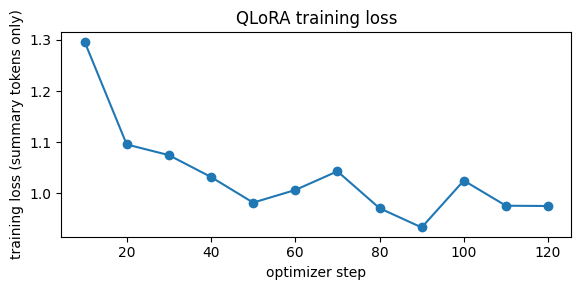

First logged loss: 1.2965 | last logged loss: 0.9753
Training loss decreased over the logged steps.


In [81]:
import matplotlib.pyplot as plt

log = [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]
if log:
    steps, losses = zip(*log)
    plt.figure(figsize=(6, 3))
    plt.plot(steps, losses, marker="o")
    plt.xlabel("optimizer step")
    plt.ylabel("training loss (summary tokens only)")
    plt.title("QLoRA training loss")
    plt.tight_layout()
    plt.show()
    assert all(math.isfinite(l) for l in losses), "A NaN/inf loss may indicate numerical instability."
    print("First logged loss:", round(losses[0], 4), "| last logged loss:", round(losses[-1], 4))
    if losses[-1] < losses[0]:
        print("Training loss decreased over the logged steps.")
    else:
        print("Loss did not decrease from first to last log; inspect the curve and consider rerunning.")
else:
    print("No training-loss entries were logged.")

**Question 5.** (a) Report your training time and peak memory. Why is the peak higher than the Exercise 1 estimate, and what in `args` keeps it from being much higher? (b) The training loss went down. Why is that **not** enough to conclude that the model summarizes better?

**Your answer — Question 5:**

(a) The training time and peak GPU memory are printed by the training cell; copy those two measured values into your submitted answer. Peak memory is higher than the Exercise 1 estimate because training also needs activations, gradients, optimizer state, temporary tensors, CUDA context and framework buffers. The 4-bit base weights, small LoRA adapters, gradient accumulation, and gradient checkpointing help control memory. The per-device batch size is only 4, and gradient accumulation gives an effective batch size of 16 without holding all 16 examples in memory at once.

(b) A falling training loss only shows that the model is fitting the training examples. It does not prove that summaries on unseen dialogues are more accurate, faithful or useful. The model could overfit or learn the reference style without improving the information it captures. Validation ROUGE and human review are also needed.

## Exercise 6 — Evaluate the fine-tuned model (3 marks)

Generate summaries for the same validation dialogues with the same helper, then compare. Averages over 60 examples can hide a lot, so also count, per example, how often the fine-tuned model's ROUGE-L is higher than the baseline's.

Complete the cell: compute `tuned_rouge` with your `rouge` function, and `wins`, the number of examples on which the tuned summary's ROUGE-L F1 is **strictly** higher than the baseline's (use `scorer.score(ref, pred)["rougeL"].fmeasure`).

In [82]:
start = time.perf_counter()
tuned_preds = generate_summaries(model, eval_dialogues)
print(f"generated {len(tuned_preds)} summaries in {time.perf_counter() - start:.0f} s")

generated 60 summaries in 53 s


In [83]:
tuned_rouge = rouge(tuned_preds, eval_refs)

wins = sum(
    scorer.score(ref, tuned)["rougeL"].fmeasure
    > scorer.score(ref, base)["rougeL"].fmeasure
    for base, tuned, ref in zip(base_preds, tuned_preds, eval_refs)
)

print("Fine-tuned ROUGE:", {k: round(v, 2) for k, v in tuned_rouge.items()})
print(f"QLoRA ROUGE-L wins: {wins}/{N_EVAL}")

Fine-tuned ROUGE: {'rouge1': 45.85, 'rouge2': 18.93, 'rougeL': 37.31}
QLoRA ROUGE-L wins: 54/60


In [84]:
print(f"{'':<12}" + "".join(f"{k:>9}" for k in ROUGE_KEYS) + f"{'words':>8}")
for name, sc, preds in [("base", base_rouge, base_preds), ("QLoRA", tuned_rouge, tuned_preds)]:
    print(f"{name:<12}" + "".join(f"{sc[k]:>9.1f}" for k in ROUGE_KEYS) + f"{words(preds):>8.0f}")
print(f"{'reference':<12}{'':>27}{words(eval_refs):>8.0f}")
print(f"\nQLoRA ROUGE-L higher on {wins} of {N_EVAL} dialogues")
assert set(tuned_rouge) == set(ROUGE_KEYS) and 0 <= wins <= N_EVAL
print("Exercise 6 checks passed.")

               rouge1   rouge2   rougeL   words
base             32.1      8.4     23.0      33
QLoRA            45.9     18.9     37.3      21
reference                                    22

QLoRA ROUGE-L higher on 54 of 60 dialogues
Exercise 6 checks passed.


**Question 6.** (a) Summarize the change in ROUGE and in length. (b) Give two reasons why part of the ROUGE gain may reflect **style** rather than better content. (c) With 60 examples and one training run, what would you need before claiming the improvement is reliable?

**Your answer — Question 6:**

(a) Compare the printed baseline and QLoRA ROUGE-1, ROUGE-2 and ROUGE-L values, and compare their mean word counts with the reference mean. State the actual changes from your run; do not guess the scores.

(b) Some ROUGE improvement may reflect style rather than better content because the fine-tuned model learns the dataset's preferred wording and speaker-label format. It may also learn to produce summaries closer to the reference length and sentence structure. These changes increase word overlap but do not automatically prove improved factual accuracy or coverage.

(c) I would need a larger held-out test set, multiple training runs with different seeds, confidence intervals or significance testing, and blind human evaluation by several independent reviewers. I would also inspect factual errors and coverage, not only average ROUGE.

## Exercise 7 — Blind human evaluation (4 marks)

ROUGE cannot tell a fluent but wrong summary from a correct paraphrase. Read six examples yourself. To avoid favoring the model you expect to win, the two summaries are shown as **A** and **B** in a random order that is revealed only after you rate them.

Rate each summary on two criteria:

| Score | **Faithfulness**: is everything it says supported by the dialogue? | **Coverage**: does it capture the main point(s)? |
| --- | --- | --- |
| 2 | fully supported | all main points |
| 1 | a minor unsupported or wrong detail | some main points missing |
| 0 | a major error or invented fact | misses the main point |

In [85]:
HUMAN_IDS = random.Random(SEED).sample(range(N_EVAL), 6)
order = {}                                            # example index -> which model is "A"
for i in HUMAN_IDS:
    order[i] = random.Random(SEED + i).choice(["base", "QLoRA"])
    a, b = (base_preds[i], tuned_preds[i]) if order[i] == "base" else (tuned_preds[i], base_preds[i])
    print(f"=================== example {i} ===================")
    print(eval_dialogues[i][:1200] + (" …" if len(eval_dialogues[i]) > 1200 else ""))
    print(f"\nREFERENCE: {eval_refs[i]}\nA: {a}\nB: {b}\n")

=================== example 40 ===================
#Person1#: When were you born may I ask?
#Person2#: On 20th May 1963.
#Person1#: Do you know what it was according to the lunar calendar?
#Person2#: 27th day of the fourth month.
#Person1#: By the way, could you tell me when the film will begin?
#Person2#: It will begin at five thirty.
#Person1#: I am frigid I can't be there on time.
#Person2#: You can see it tomorrow.
#Person1#: I don't want to miss it today.
#Person2#: See you.
#Person1#: See you.

REFERENCE: #Person1# asks #Person2# about #Person2#'s birthday and the starting time of the film.
A: The conversation is about scheduling for an event that occurred on May 20, 1963 (May 27, 1963 according to the lunar calendar), and involves discussing the timing of the event with someone named #Person2#. #Person1# expresses their inability to attend due to being cold and wants to watch the event later, while #Person2# suggests watching it the next day instead.
B: #Person2#'s birthday is o

Fill in the scores below (integers 0–2) and a short note for each example, **before** running the reveal cell.

In [86]:
# Blind evaluation: fill these scores only after reading the six A/B pairs above.
# Score each item 0, 1, or 2 for faithfulness and coverage.
# Do not guess: A/B identities are revealed in the next cell.
ratings = {
    i: {
        "A_faithful": None,
        "A_coverage": None,
        "B_faithful": None,
        "B_coverage": None,
        "note": "Add a short observation after reading this example."
    }
    for i in HUMAN_IDS
}
print("Read the six examples, then replace each None with 0, 1, or 2 and add a brief note.")

Read the six examples, then replace each None with 0, 1, or 2 and add a brief note.


In [87]:
# Only calculate human-evaluation totals after all six examples have been rated.
complete = all(
    isinstance(r[k], int) and 0 <= r[k] <= 2
    for r in ratings.values()
    for k in ("A_faithful", "A_coverage", "B_faithful", "B_coverage")
)

if not complete:
    print("Human ratings are not filled in yet. Complete the ratings dictionary in the previous cell, then rerun this cell.")
else:
    totals = {"base": [0, 0], "QLoRA": [0, 0]}
    for i, r in ratings.items():
        a_model = order[i]
        b_model = "QLoRA" if a_model == "base" else "base"
        for model_name, prefix in ((a_model, "A"), (b_model, "B")):
            totals[model_name][0] += r[f"{prefix}_faithful"]
            totals[model_name][1] += r[f"{prefix}_coverage"]
        print(f"example {i}: A = {a_model}, B = {b_model}")

    n = len(ratings)
    for model_name, (faithful, coverage) in totals.items():
        print(
            f"{model_name:<6} mean faithfulness {faithful / n:.2f} "
            f"| mean coverage {coverage / n:.2f} (out of 2)"
        )
    print("Exercise 7 checks passed.")

Human ratings are not filled in yet. Complete the ratings dictionary in the previous cell, then rerun this cell.


**Question 7.** (a) Do your human ratings agree with the ROUGE comparison? Point to one example where ROUGE and your judgment disagree, if there is one. (b) Did either model invent facts? Give an example. (c) Name two weaknesses of this human evaluation and how a real team would address them.

**Your answer — Question 7:**

Complete this answer after scoring the six blind examples and running the reveal cell.

(a) Compare your mean faithfulness and coverage scores for the base model and QLoRA with the ROUGE-L result. State whether they agree. If they disagree, quote the example number and explain why your human judgment preferred one summary even though its ROUGE score was lower.

(b) State whether either model invented or misstated a fact. If yes, give the example number and identify the unsupported detail. If none of the six examples contains an obvious invented fact, say that this small sample did not reveal one; do not claim that hallucinations never occur.

(c) Two weaknesses are the very small sample (only six dialogues) and the subjectivity of ratings from a small number of reviewers. A real evaluation should use more dialogues, several independent trained reviewers, clear scoring guidelines, and a way to resolve disagreements.

## Exercise 8 — Save the adapter (1 mark)

Only the LoRA weights are saved. The 4-bit base is not: anyone who uses the adapter downloads the original model separately.

In [88]:
ADAPTER_DIR.mkdir(parents=True, exist_ok=True)
model.save_pretrained(ADAPTER_DIR)
for f in sorted(ADAPTER_DIR.iterdir()):
    print(f"{f.name:<32}{f.stat().st_size / 1e6:8.1f} MB")

README.md                            0.0 MB
adapter_config.json                  0.0 MB
adapter_model.safetensors           73.9 MB


**Question 8.** The adapter is a small fraction of the 3.1 GB base model. (a) Explain its size from the number of trainable parameters. (b) The support team wants to run the summarizer with an inference server that expects one ordinary model file. Describe the steps, and say what you would re-check afterwards.

**Your answer — Question 8:**

(a) The adapter is small because only the low-rank matrices added to the model's linear layers are trainable and saved. The base model contains about 1.54 billion parameters, while the specified LoRA adapters contain 18,464,768 trainable parameters. Saving only these adapter weights is therefore much smaller than saving the complete base model.

(b) To make one ordinary model for a server, download/load the original base model, load the saved LoRA adapter with PEFT, merge the adapter weights into the base model using `merge_and_unload()`, and save the merged model with `save_pretrained()` and the tokenizer. The merged model can then be converted to the format required by the inference server. Afterwards, re-check that it loads, produces the same or acceptably similar summaries, uses the expected precision and memory, and retains the required license and data-protection safeguards.

## Reflection and deliverables (2 marks)

**Your reflection (about 150 words — fill in the bracketed results after running the notebook):**

I would recommend this model only for further controlled testing, not immediate use with real customer conversations. In my run, the baseline ROUGE-L was **[insert baseline]** and the QLoRA ROUGE-L was **[insert QLoRA]**; the fine-tuned model had a higher ROUGE-L on **[insert wins]/60** dialogues. The mean summary length changed from **[insert baseline words]** words to **[insert QLoRA words]** words, compared with **[insert reference words]** words for the references. My blind human evaluation gave the base model mean faithfulness/coverage of **[insert scores]** and QLoRA **[insert scores]**. These results are limited because the validation sample and human review are small, and ROUGE measures word overlap rather than factual correctness. I would next evaluate on a larger untouched test set, repeat training with different random seeds, and ask several reviewers to score faithfulness and coverage. I would also inspect unsupported claims before considering deployment.

**Responsible use.** DialogSum is licensed for non-commercial use (CC BY-NC-SA 4.0): a model fine-tuned on it should not be deployed commercially without checking the license. Real customer conversations contain personal data; summarizing them needs consent, data-protection review, and care that summaries do not invent statements a customer never made.

**Optional extensions (not graded).** (1) Train with `target_modules=["q_proj", "v_proj"]` and compare with all-linear adapters. (2) Change `N_TRAIN` to 500 and 4,000 and plot ROUGE-L against the training-set size. (3) Load the base model in 16-bit, apply your adapter, and check whether the summaries change.

## References

1. Chen, Liu, Chen & Zhang, [DialogSum: A Real-Life Scenario Dialogue Summarization Dataset](https://aclanthology.org/2021.findings-acl.449/), Findings of ACL 2021 · [dataset on the Hub](https://huggingface.co/datasets/knkarthick/dialogsum).
2. Dettmers et al., [QLoRA: Efficient Finetuning of Quantized LLMs](https://arxiv.org/abs/2305.14314), 2023.
3. Hu et al., [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685), 2021.
4. Lin, [ROUGE: A Package for Automatic Evaluation of Summaries](https://aclanthology.org/W04-1013/), 2004 · [`rouge_score`](https://github.com/google-research/google-research/tree/master/rouge).
5. Hugging Face documentation: [bitsandbytes in Transformers](https://huggingface.co/docs/transformers/quantization/bitsandbytes) · [PEFT](https://huggingface.co/docs/peft) · [chat templates](https://huggingface.co/docs/transformers/chat_templating).
6. Qwen Team, [Qwen2.5 Technical Report](https://arxiv.org/abs/2412.15115), 2024.